In [4]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import random

In [5]:
def creategraph(G,plant):
   protein_csv = f"dataset/datacsv/{plant}.csv" 
   protein_scores_csv = f"dataset/protein_scores/{plant}.csv"

   proteins = pd.read_csv(protein_csv)
   score_data = pd.read_csv(protein_scores_csv)
   G.add_nodes_from(proteins['Proteins'].tolist())
   edges = []
   for row in score_data.itertuples():
      edges.append((row.Protein1,row.Protein2,row.Score))
   G.add_weighted_edges_from(edges)
   

In [6]:
def display(G,node_size=20,position=False):
    if position:
        positions = {i: (random.uniform(-1, 1), random.uniform(-1, 1)) for i in G.nodes()}
        nx.draw(G,pos=positions, with_labels=False, node_size=node_size)
    else:
        nx.draw(G, with_labels=False, node_size=node_size)
    plt.show()

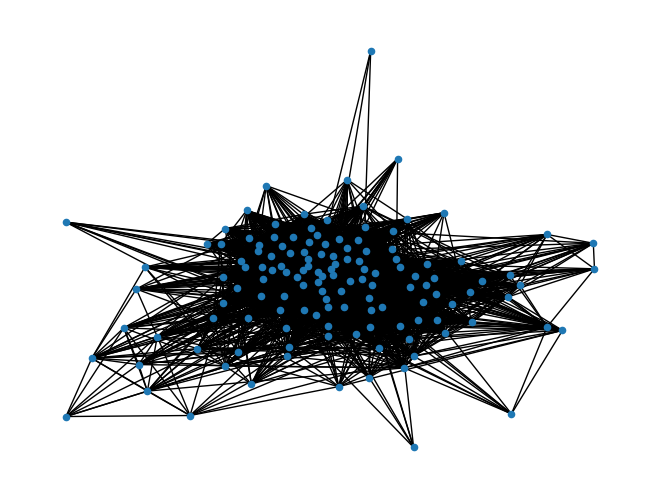

Number of nodes:  134
Number of edges:  3990


In [7]:
G1 = nx.Graph()
creategraph(G1,"Terminalia_arjuna")
display(G1)
print("Number of nodes: ",len(G1.nodes))
print("Number of edges: ",len(G1.edges))

## MCL

In [8]:
from scipy.sparse import csr_matrix
array = nx.to_scipy_sparse_array(G1, format="csr")
sparse_matrix = csr_matrix(array)

In [9]:
import markov_clustering as mc
infl=0;modul=0
for inflation in [i / 10 for i in range(11, 26)]:
    result = mc.run_mcl(sparse_matrix, inflation=inflation)
    clusters = mc.get_clusters(result)
    Q = mc.modularity(matrix=result, clusters=clusters)
    print("inflation:", inflation, "modularity:", Q)
    if Q>modul:
        modul=Q;infl=inflation

inflation: 1.1 modularity: 0.0
inflation: 1.2 modularity: 0.0
inflation: 1.3 modularity: 0.007351303185564735
inflation: 1.4 modularity: 0.007351303185564735
inflation: 1.5 modularity: 0.007351303185564735
inflation: 1.6 modularity: 0.007351303185564735
inflation: 1.7 modularity: 0.036088215638226825
inflation: 1.8 modularity: 0.08476275339719323
inflation: 1.9 modularity: 0.08476275339719323
inflation: 2.0 modularity: 0.08476275339719323
inflation: 2.1 modularity: 0.08476275339719323
inflation: 2.2 modularity: 0.0982401425707285
inflation: 2.3 modularity: 0.0982401425707285
inflation: 2.4 modularity: 0.13154377366896844
inflation: 2.5 modularity: 0.13154377366896844


In [10]:
result = mc.run_mcl(sparse_matrix,inflation=infl)
markov_clusters = mc.get_clusters(result)
for i in markov_clusters:
    print(i)

(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 25, 26, 27, 28, 29, 31, 32, 33, 34, 35, 38, 39, 41, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 95, 96, 98, 99, 101, 104, 105, 106, 107, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133)
(22, 36, 37, 40, 42)
(30,)
(94, 102, 103)
(97, 100)
(108,)


In [11]:
import numpy as np
from sklearn.metrics import silhouette_score

def calculate_silhouette(sparse_matrix, clusters):
    """
    Calculate Silhouette Score for MCL clusters in a weighted PPI network.
    
    Args:
        sparse_matrix: scipy.sparse adjacency matrix of the PPI network
        clusters: List of clusters from MCL (each cluster is a list of node indices)
        
    Returns:
        Silhouette Score between -1 and 1
    """
    adj_matrix = sparse_matrix.toarray()
    n_nodes = adj_matrix.shape[0]
    labels = -np.ones(n_nodes, dtype=int)
    for cluster_id, cluster in enumerate(clusters):
        labels[np.array(cluster)] = cluster_id
    # Convert adjacency weights to distances (higher weight = smaller distance)
    # Add epsilon to avoid division by zero
    distance_matrix = 1 / (adj_matrix + 1e-8)
    np.fill_diagonal(distance_matrix, 0)  # Zero distance to self

    return silhouette_score(distance_matrix, labels, metric='precomputed')

In [12]:
silh = {}
silh['markov'] = calculate_silhouette(sparse_matrix=sparse_matrix,clusters=markov_clusters)
print(silh['markov'])

0.11052042929957444


## Affinity Propogation

In [13]:
from sklearn.cluster import AffinityPropagation
nodes = list(G1.nodes())
n = len(nodes)
dist_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        try:
            if i != j:
                dist_matrix[i][j] = nx.shortest_path_length(G1, source=nodes[i], target=nodes[j])
        except nx.NetworkXNoPath:
            dist_matrix[i][j] = np.inf  # No connection

# Convert to similarity matrix (Affinity Propagation uses similarity, not distance)
# We'll use negative distances, and inf will be replaced by large negative numbers
similarity_matrix = -dist_matrix
similarity_matrix[similarity_matrix == -np.inf] = -1e5
similarity_matrix[similarity_matrix == 0] = -1  # Avoid zero similarity for same node

# Run Affinity Propagation
affprop = AffinityPropagation(affinity='precomputed', random_state=42)
labels = affprop.fit_predict(similarity_matrix)

# Group nodes by cluster
clusters = {}
for node, label in zip(nodes, labels):
    clusters.setdefault(label, []).append(node)

In [14]:
for i,j in clusters.items():
    print(j)

['DHDH', 'AKR1C4', 'LRTOMT', 'SULT1C2', 'SULT1A2', 'SULT1A3', 'CASP8', 'NOS3', 'NR1I3', 'SERPINE1', 'ALOX15', 'MAP2K1', 'GSK3B', 'CYP1A2', 'PLAU', 'CAT', 'TLR4', 'SLC2A4', 'TOP1', 'UGT2B11', 'ICAM1', 'DHCR24']
['MPO', 'LPO', 'LCN2', 'HMBS', 'CASP3', 'HBB', 'CSNK2A1', 'MMP2', 'RETN', 'SQLE', 'CA2', 'PRKACA', 'CA5A', 'CA5B', 'CA7', 'CA14', 'CA6', 'NME2', 'PRKCA', 'KEAP1', 'INS', 'CDK2', 'TNFRSF10B', 'MITF', 'DDIT4', 'CYP3A4', 'UGT2B15', 'MMP9', 'CYP1A1', 'CDK1', 'RELA', 'DAO', 'LTF', 'AFP', 'PC', 'TF', 'TGFB1', 'HMOX1', 'ANO1', 'UGT2B10', 'PTGIR', 'HMGB1', 'TOP2A', 'APOE', 'ABCG5', 'ABCB11', 'SREBF2']
['EPX', 'TYR', 'PRDX5', 'PLA2G1B', 'CASP9', 'COMT', 'CASP7', 'GCG', 'PRKCB', 'SYK', 'MAPK1', 'NFKB1', 'CCND1', 'ALOX12', 'CDK4', 'MAPK3', 'TP53', 'NOTCH1', 'NFKBIB', 'PKM', 'NR1I2', 'S100A7', 'MCL1', 'PCK1', 'KCNT2', 'NFAT5', 'SI', 'NAMPT', 'CYP7A1', 'SREBF1']
['AKR1C1', 'CA12', 'CCL2', 'TMPRSS11D', 'PARG', 'CFTR', 'CCNB1', 'CYP1B1', 'AKT1', 'HSD11B2', 'NOS1', 'MAPK8', 'PTGS1', 'ABCC1', 'PC

In [15]:
dist_matrix[dist_matrix == np.inf] = 1e5
ap_sil_score = silhouette_score(dist_matrix, labels, metric='precomputed')

print("Silhouette Score for Affinity Propagation:", ap_sil_score)
silh['AP'] = ap_sil_score

Silhouette Score for Affinity Propagation: -0.05277553275777149


## Louvain Method

In [16]:
import community.community_louvain as community_louvain
partition_louvain = community_louvain.best_partition(G1)
louvain_clusters = {}
for node, cluster_id in partition_louvain.items():
    louvain_clusters.setdefault(cluster_id, []).append(node)

In [17]:
for i,j in louvain_clusters.items():
    print(j)

['DHDH', 'AKR1C4', 'LRTOMT', 'SULT1C2', 'SULT1A2', 'SULT1A3', 'COMT', 'AKR1C1', 'SQLE', 'NR1I3', 'CYP1B1', 'HSD11B2', 'NR1I2', 'CYP3A4', 'UGT2B15', 'CYP1A2', 'CYP1A1', 'ABCC1', 'AMFR', 'UBE2G2', 'PPARA', 'UGT2B10', 'UGT2B11', 'ABCG5', 'ABCB11', 'ABCG8', 'CYP7A1', 'SREBF1', 'SREBF2', 'DHCR24']
['MPO', 'EPX', 'LCN2', 'PLA2G1B', 'GCG', 'MMP2', 'RETN', 'CCL2', 'TMPRSS11D', 'NOS3', 'SERPINE1', 'ALOX12', 'IL6', 'ALOX15', 'NOS2', 'NOS1', 'PTGS1', 'PTGS2', 'S100A7', 'MMP9', 'PLAU', 'LTF', 'TGFB1', 'KCNT2', 'TLR4', 'HMOX1', 'SLC2A4', 'SI', 'NAMPT', 'PTGIR', 'APOE', 'ICAM1']
['LPO', 'PRDX5', 'HMBS', 'HBB', 'CA12', 'CA1', 'PGD', 'CA2', 'CA3', 'CA5A', 'CA5B', 'CA7', 'CA14', 'CA6', 'CA9', 'NME1-NME2', 'NME2', 'G6PD', 'CFTR', 'INS', 'PKM', 'PCK2', 'DAO', 'CAT', 'PCK1', 'ME2', 'HOGA1', 'HAO1', 'AFP', 'PC', 'TF', 'LDHA', 'ANO1']
['TYR', 'CASP3', 'CASP9', 'CASP8', 'CASP7', 'CSNK2A1', 'PRKCB', 'PRKACA', 'SYK', 'PARG', 'PRKCA', 'KEAP1', 'MAPK1', 'NFKB1', 'CCND1', 'CCNB1', 'CDK4', 'MAPK3', 'CDK2', 'TP53',

In [18]:
labels = np.array([partition_louvain[node] for node in nodes])

# Step 3: Compute shortest-path distance matrix
dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        if i != j:
            try:
                dist_matrix[i][j] = nx.shortest_path_length(G1, source=nodes[i], target=nodes[j])
            except nx.NetworkXNoPath:
                dist_matrix[i][j] = np.inf  # no path = infinite distance

# Step 4: Prepare for silhouette score
# Replace inf with a large value to make distances computable
dist_matrix[dist_matrix == np.inf] = 1e5

# Step 5: Compute Silhouette Score
if len(set(labels)) > 1:
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    silh['Louvain'] = score
    print("Silhouette Score for Louvain Clustering:", score)
else:
    print("Only one cluster found. Silhouette Score is undefined.")

Silhouette Score for Louvain Clustering: 0.10583511827354507


## Infomap

In [19]:
from infomap import Infomap

nodes = list(G1.nodes())
n = len(nodes)

# Step 2: Map nodes to integers for Infomap
node_to_int = {node: i for i, node in enumerate(nodes)}
int_to_node = {i: node for node, i in node_to_int.items()}

# Step 3: Run Infomap with integer node IDs
im = Infomap()
for u, v in G1.edges():
    im.add_link(node_to_int[u], node_to_int[v])

im.run()

# Step 4: Extract cluster labels
infomap_labels = -np.ones(n, dtype=int)
infomap_clusters = {}
for node in im.nodes:
    original_node = int_to_node[node.node_id]
    original_index = nodes.index(original_node)
    infomap_labels[original_index] = node.module_id
    infomap_clusters.setdefault(node.module_id, []).append(node.node_id)

In [20]:
for i,j in infomap_clusters.items():
    print(j)

[55, 59, 64, 63, 10, 61, 53, 83, 125, 118, 90, 112, 86, 74, 26, 110, 107, 46, 50, 101, 88, 54, 128, 35, 49, 78, 114, 131, 80, 62, 51, 113, 73, 81, 1, 52, 58, 33, 13, 89, 24, 69, 60, 17, 75, 21, 91, 87, 76, 5, 92, 121, 66, 48, 7, 104, 57, 132, 82, 85, 95, 43, 124, 130, 18, 117, 28, 109, 41, 70, 127, 67, 98, 19, 115, 65, 77, 34, 93, 39, 133, 68, 25, 9, 14, 8, 71, 31, 105, 20, 6, 72, 103, 96, 126, 111, 56, 29, 122, 129, 23, 119, 94, 79, 123, 27, 45, 22, 4, 32, 106, 84, 116, 11, 42, 3, 97, 0, 2, 40, 120, 16, 99, 12, 44, 38, 15, 36, 47, 30, 102, 37, 100, 108]


In [21]:
# Step 5: Compute shortest-path distance matrix
dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        if i != j:
            try:
                dist_matrix[i][j] = nx.shortest_path_length(G1, source=nodes[i], target=nodes[j])
            except nx.NetworkXNoPath:
                dist_matrix[i][j] = np.inf

# Step 6: Replace inf with a large number
dist_matrix[dist_matrix == np.inf] = 1e5

# Step 7: Compute Silhouette Score
if len(set(infomap_labels)) > 1:
    sil_score = silhouette_score(dist_matrix, infomap_labels, metric='precomputed')
    silh['Infomap'] = sil_score
    print("Silhouette Score for Infomap Clustering:", sil_score)
else:
    print("Only one cluster found. Silhouette Score is undefined.")
    silh['Infomap'] = np.float64(-1)


Only one cluster found. Silhouette Score is undefined.


## Spectral Clustering

In [22]:
from sklearn.cluster import SpectralClustering

# Step 1: Create or load your graph (replace this with your actual G)
nodes = list(G1.nodes())
n = len(nodes)

# Step 2: Spectral Clustering (affinity='precomputed')
adj_matrix = nx.to_numpy_array(G1)
sc = SpectralClustering(n_clusters=2, affinity='precomputed', assign_labels='kmeans', random_state=42)
labels = sc.fit_predict(adj_matrix)

# Step 3: Build cluster dictionary (optional, just for clarity)
spectral_clusters = {}
for idx, label in enumerate(labels):
    spectral_clusters.setdefault(label, []).append(idx)

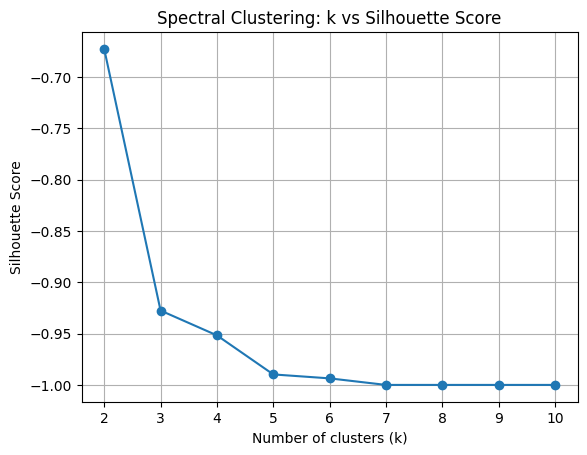


✅ Best k based on silhouette score: 2, Score: -0.6728


In [23]:
adj_matrix = nx.to_numpy_array(G1)
best_k = None
best_score = -1
scores = []

for k in range(2, 11):
    sc = SpectralClustering(n_clusters=k, affinity='precomputed', assign_labels='kmeans', random_state=42)
    labels = sc.fit_predict(adj_matrix)

    if len(set(labels)) > 1:  # Avoid 1-cluster case
        score = silhouette_score(adj_matrix, labels, metric='precomputed')
        scores.append((k, score))
        if score > best_score:
            best_score = score
            best_k = k
    else:
        scores.append((k, -1))  # Invalid silhouette

# Plot
ks, svals = zip(*scores)
plt.plot(ks, svals, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Spectral Clustering: k vs Silhouette Score")
plt.grid(True)
plt.show()

print(f"\n✅ Best k based on silhouette score: {best_k}, Score: {best_score:.4f}")


In [24]:
for i,j in spectral_clusters.items():
    print(j)

[0, 3, 4, 9, 12, 15, 16, 18, 20, 22, 27, 28, 29, 32, 36, 37, 38, 39, 40, 42, 60, 76, 78, 79, 80, 88, 94, 96, 97, 99, 100, 102, 103, 105, 106, 119, 123, 126, 127, 129, 130, 133]
[1, 2, 5, 6, 7, 8, 10, 11, 13, 14, 17, 19, 21, 23, 24, 25, 26, 30, 31, 33, 34, 35, 41, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 77, 81, 82, 83, 84, 85, 86, 87, 89, 90, 91, 92, 93, 95, 98, 101, 104, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 120, 121, 122, 124, 125, 128, 131, 132]


In [25]:
dist_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        if i != j:
            try:
                dist_matrix[i][j] = nx.shortest_path_length(G1, source=nodes[i], target=nodes[j])
            except nx.NetworkXNoPath:
                dist_matrix[i][j] = np.inf
dist_matrix[dist_matrix == np.inf] = 1e5

if len(set(labels)) > 1:
    sil_score = silhouette_score(dist_matrix, labels, metric='precomputed')
    silh['Spectral'] = sil_score
    print("Silhouette Score for Spectral Clustering:", sil_score)
else:
    print("Only one cluster found. Silhouette Score is undefined.")
    silh['Spectral'] = np.float64(-1)

Silhouette Score for Spectral Clustering: 0.03704422677821841


## Leiden

In [26]:
import igraph as ig
import leidenalg

# --- Step 1: Convert NetworkX graph to igraph ---
def nx_to_igraph(G):
    mapping = {node: idx for idx, node in enumerate(G.nodes())}
    G_ig = ig.Graph()
    G_ig.add_vertices(len(mapping))
    edges = [(mapping[u], mapping[v]) for u, v in G.edges()]
    G_ig.add_edges(edges)

    # Optionally, add weights
    if nx.get_edge_attributes(G, 'weight'):
        weights = [G[u][v].get('weight', 1.0) for u, v in G.edges()]
        G_ig.es['weight'] = weights

    return G_ig, mapping

# --- Step 2: Run Leiden ---
def leiden_clustering(G):
    G_ig, mapping = nx_to_igraph(G)
    partition = leidenalg.find_partition(G_ig, leidenalg.ModularityVertexPartition)
    clusters = [list(comm) for comm in partition]
    # Reverse mapping from igraph ID to original node
    reverse_mapping = {v: k for k, v in mapping.items()}
    clusters_named = [[reverse_mapping[node] for node in cluster] for cluster in clusters]
    return clusters_named

clusters_leiden = leiden_clustering(G1)

In [27]:
for i in clusters_leiden:
    print(i)

['MPO', 'EPX', 'LCN2', 'PLA2G1B', 'CASP9', 'CASP8', 'CASP7', 'CSNK2A1', 'MMP2', 'RETN', 'CCL2', 'NOS3', 'PRKCB', 'PRKACA', 'SYK', 'PARG', 'PRKCA', 'KEAP1', 'MAPK1', 'SERPINE1', 'NFKB1', 'CCND1', 'ALOX12', 'CCNB1', 'CDK4', 'MAPK3', 'CDK2', 'TNFRSF10B', 'NOTCH1', 'ALOX15', 'MITF', 'MAP2K1', 'DDIT4', 'NFKBIB', 'GSK3B', 'NOS2', 'NOS1', 'MAPK8', 'PTGS1', 'PTGS2', 'MCL1', 'MMP9', 'PLAU', 'CDK1', 'NFE2L2', 'RELA', 'SRC', 'TGFB1', 'KCNT2', 'PTK2', 'TLR4', 'NFAT5', 'SLC2A4', 'NAMPT', 'PTGIR', 'HMGB1', 'TOP1', 'TOP2A', 'APOE', 'ICAM1']
['DHDH', 'AKR1C4', 'LRTOMT', 'SULT1C2', 'SULT1A2', 'SULT1A3', 'COMT', 'AKR1C1', 'GCG', 'SQLE', 'PGD', 'NR1I3', 'G6PD', 'CYP1B1', 'AKT1', 'HSD11B2', 'NR1I2', 'CYP3A4', 'UGT2B15', 'CYP1A2', 'CYP1A1', 'ABCC1', 'PCK2', 'DAO', 'CAT', 'AMFR', 'PCK1', 'UBE2G2', 'HOGA1', 'HAO1', 'HMOX1', 'SI', 'PPARA', 'UGT2B10', 'UGT2B11', 'ABCG5', 'ABCB11', 'ABCG8', 'CYP7A1', 'SREBF1', 'SREBF2', 'DHCR24']
['LPO', 'TYR', 'PRDX5', 'HMBS', 'CASP3', 'HBB', 'CA12', 'CA1', 'TMPRSS11D', 'CA2',

In [28]:
# --- Step 3: Silhouette Score ---
def leiden_silhouette_score(G, clusters):
    node_list = list(G.nodes())
    idx_map = {node: i for i, node in enumerate(node_list)}

    # Adjacency matrix to distance matrix
    adj_matrix = nx.to_numpy_array(G, nodelist=node_list)
    dist_matrix = 1 / (adj_matrix + 1e-8)
    np.fill_diagonal(dist_matrix, 0)

    labels = -np.ones(len(node_list), dtype=int)
    for cluster_id, cluster in enumerate(clusters):
        for node in cluster:
            labels[idx_map[node]] = cluster_id

    return silhouette_score(dist_matrix, labels, metric='precomputed')
score = leiden_silhouette_score(G1, clusters_leiden)
print(f"Silhouette Score: {score:.4f}")
silh['Leiden'] = score

Silhouette Score: 0.3733


## Restricted Neighborhood Search Clustering (RNSC)

In [29]:
from collections import defaultdict

def initial_partition(G, k):
    """Randomly assign nodes to k clusters."""
    nodes = list(G.nodes())
    random.shuffle(nodes)
    clusters = {i: [] for i in range(k)}
    for i, node in enumerate(nodes):
        clusters[i % k].append(node)
    return clusters

def compute_cost(G, clusters):
    """Compute inter-cluster edge cost."""
    cost = 0
    node_cluster = {}
    for cid, nodes in clusters.items():
        for node in nodes:
            node_cluster[node] = cid

    for u, v in G.edges():
        if node_cluster.get(u) != node_cluster.get(v):
            cost += 1  # can also weight this by edge weight if desired

    return cost

def move_node(G, clusters, node_cluster_map):
    """Try moving a random node to another cluster and see if cost decreases."""
    all_nodes = list(G.nodes())
    node = random.choice(all_nodes)
    current_cluster = node_cluster_map[node]
    candidate_clusters = list(clusters.keys())
    candidate_clusters.remove(current_cluster)

    best_cluster = current_cluster
    best_cost = None

    for new_cluster in candidate_clusters:
        # Temporarily move node
        clusters[current_cluster].remove(node)
        clusters[new_cluster].append(node)
        node_cluster_map[node] = new_cluster

        temp_cost = compute_cost(G, clusters)

        # Restore
        clusters[new_cluster].remove(node)
        clusters[current_cluster].append(node)
        node_cluster_map[node] = current_cluster

        if best_cost is None or temp_cost < best_cost:
            best_cost = temp_cost
            best_cluster = new_cluster

    if best_cluster != current_cluster:
        clusters[current_cluster].remove(node)
        clusters[best_cluster].append(node)
        node_cluster_map[node] = best_cluster
        return True  # Move accepted

    return False  # No better move found

def rnsc(G, k=4, iterations=1000):
    clusters = initial_partition(G, k)
    node_cluster_map = {}
    for cid, nodes in clusters.items():
        for node in nodes:
            node_cluster_map[node] = cid

    for _ in range(iterations):
        moved = move_node(G, clusters, node_cluster_map)
        if not moved:
            break

    # Clean empty clusters
    clusters = {cid: nodes for cid, nodes in clusters.items() if nodes}

    return clusters

In [30]:
def silhouette_score_rnsc(G, clusters):
    node_list = list(G.nodes())
    idx_map = {node: i for i, node in enumerate(node_list)}
    adj_matrix = nx.to_numpy_array(G, nodelist=node_list)
    dist_matrix = 1 / (adj_matrix + 1e-8)
    np.fill_diagonal(dist_matrix, 0)

    labels = -np.ones(len(node_list), dtype=int)
    for cid, nodes in clusters.items():
        for node in nodes:
            labels[idx_map[node]] = cid

    return silhouette_score(dist_matrix, labels, metric='precomputed')

In [31]:
best_k = None
best_score = -1
best_clusters = None

for k in range(2, 12):
    clusters = rnsc(G1, k=k, iterations=1000)
    score = silhouette_score_rnsc(G1, clusters)
    print(f"k = {k}, Silhouette Score = {score:.4f}")
    if score > best_score:
        best_score = score
        best_k = k
        best_clusters = clusters

print(f"Best k = {best_k}, Best Score = {best_score:.4f}")
silh['RNSC'] = best_score

k = 2, Silhouette Score = -0.0216
k = 3, Silhouette Score = -0.0251
k = 4, Silhouette Score = 0.0208
k = 5, Silhouette Score = -0.0409
k = 6, Silhouette Score = -0.0121
k = 7, Silhouette Score = -0.0485
k = 8, Silhouette Score = -0.0079
k = 9, Silhouette Score = -0.5874
k = 10, Silhouette Score = -0.0370
k = 11, Silhouette Score = -0.4161
Best k = 4, Best Score = 0.0208


In [32]:
for i,j in best_clusters.items():
    print(j)

['ABCC1', 'CASP3', 'TLR4', 'LRTOMT', 'DDIT4', 'CYP1A2', 'TOP2A', 'DHCR24', 'CASP9', 'PRKCA', 'NR1I2', 'AKT1', 'CAT', 'APOE', 'CSNK2A1', 'PGD', 'PCK1', 'UBE2G2', 'ME2', 'MCL1', 'AKR1C1', 'TOP1', 'NOTCH1', 'COMT', 'NME2', 'MMP9', 'NOS2', 'LDHA', 'SULT1A3', 'HMBS', 'SULT1A2', 'NME1-NME2', 'PRDX5', 'TMPRSS11D', 'EPX', 'CA9', 'G6PD', 'CDK1', 'IL6', 'NFKB1', 'ALOX12', 'PKM', 'CFTR', 'CA6', 'UGT2B15', 'PARG', 'CASP7', 'NOS3', 'PLAU', 'SLC2A4', 'UGT2B11', 'CYP1B1', 'AMFR', 'AKR1C4', 'ANO1', 'PLA2G1B', 'CA5B', 'SI', 'CA14', 'HMGB1', 'NFAT5', 'NFE2L2', 'MMP2', 'HOGA1', 'CA5A', 'PTK2']
['UGT2B10', 'RELA', 'CA1', 'KCNT2', 'CDK4', 'TYR', 'NAMPT', 'CYP7A1', 'HBB', 'RETN', 'TGFB1', 'DHDH', 'MAP2K1', 'LPO', 'SYK', 'LTF', 'CYP3A4', 'CA2', 'MAPK8', 'DAO', 'NFKBIB', 'ICAM1', 'ABCG5', 'GCG', 'HSD11B2', 'TNFRSF10B', 'S100A7', 'PC', 'SERPINE1', 'PTGS1', 'CA3', 'MPO', 'PRKCB', 'NR1I3', 'CCND1', 'AFP', 'MAPK3', 'SREBF1', 'CA7', 'CDK2', 'MAPK1', 'SULT1C2', 'CA12', 'KEAP1', 'LCN2', 'PTGIR', 'SQLE', 'SRC', 'GSK3

In [33]:
silh

{'markov': np.float64(0.11052042929957444),
 'AP': np.float64(-0.05277553275777149),
 'Louvain': np.float64(0.10583511827354507),
 'Infomap': np.float64(-1.0),
 'Spectral': np.float64(0.03704422677821841),
 'Leiden': np.float64(0.3732868930236195),
 'RNSC': np.float64(0.020800717296877644)}